# EDA: Exploratory Data Analysis

## Importing needed libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay



## Reading the dataset

In [2]:
df_org = pd.read_csv("/content/Customer-Churn-Records.csv")

print(df_org.shape)

df_org.head()

(10000, 18)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [3]:
df_org.columns.tolist()

['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited',
 'Complain',
 'Satisfaction Score',
 'Card Type',
 'Point Earned']

## Data Quality Check

### 1. Check for Null Values (NaN, Null, None)

In [4]:
df_org.isna().sum().sum()

np.int64(0)

In [5]:
df = df_org.copy()

df = pd.get_dummies(df, columns=["Geography", "Gender", "Card Type"], dtype=int)

df.drop(["RowNumber", "CustomerId", "Surname"], axis=1, inplace=True)

# df = df[["CreditScore", "Age", "Tenure", "Exited"]]

df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,...,Point Earned,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male,Card Type_DIAMOND,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
0,619,42,2,0.00,1,1,1,101348.88,1,1,...,464,1,0,0,1,0,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,...,456,0,0,1,1,0,1,0,0,0
2,502,42,8,159660.80,3,1,0,113931.57,1,1,...,377,1,0,0,1,0,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,...,350,1,0,0,1,0,0,1,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,...,425,0,0,1,1,0,0,1,0,0


In [6]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=1234)

print("Train Set Shape:", train_df.shape)
print("Test Set Shape:", test_df.shape)

print("\nTrain DataFrame:")
display(train_df)

Train Set Shape: (8000, 21)
Test Set Shape: (2000, 21)

Train DataFrame:


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,...,Point Earned,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male,Card Type_DIAMOND,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
5525,624,51,10,123401.43,2,1,1,127825.25,0,0,...,242,1,0,0,0,1,0,0,0,1
5034,631,29,2,96863.52,2,1,1,31613.35,0,0,...,958,0,1,0,1,0,1,0,0,0
4709,554,31,1,0.00,2,0,1,192660.55,0,0,...,759,1,0,0,0,1,0,0,1,0
4218,589,19,9,83495.11,1,1,1,143022.31,1,1,...,747,0,1,0,1,0,0,1,0,0
917,646,45,3,47134.75,1,1,1,57236.44,0,0,...,939,1,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
664,661,41,1,0.00,2,0,1,131300.68,0,0,...,671,1,0,0,1,0,0,0,1,0
7540,553,37,1,0.00,1,1,0,30461.55,0,0,...,623,1,0,0,0,1,1,0,0,0
7221,625,41,6,97663.16,2,1,0,57128.78,0,0,...,688,1,0,0,0,1,1,0,0,0
1318,598,43,5,0.00,3,1,1,100722.72,1,1,...,858,1,0,0,1,0,0,0,0,1


In [7]:
X = train_df.drop(columns=['Exited'])  # All columns except 'Exited'
y = train_df['Exited']                 # The target column

clf_knn = KNeighborsClassifier(n_neighbors=5)

clf_knn.fit(X, y)

X_test = test_df.drop(columns=['Exited'])
y_test = test_df['Exited']

y_pred = clf_knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.761

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.94      0.86      1588
           1       0.26      0.09      0.13       412

    accuracy                           0.76      2000
   macro avg       0.53      0.51      0.50      2000
weighted avg       0.69      0.76      0.71      2000



In [8]:
# 1. Separate features (X) and target (y) for training data
X = train_df.drop(columns=['Exited'])  # All columns except 'Exited'
y = train_df['Exited']                 # The target column

# 2. Initialize the Logistic Regression Classifier
clf_logreg = LogisticRegression(random_state=1234)

# 3. Train the model
clf_logreg.fit(X, y)

# 4. Prepare test data
X_test = test_df.drop(columns=['Exited'])
y_test = test_df['Exited']

# 5. Make predictions on the test set
y_pred = clf_logreg.predict(X_test)

# 6. Evaluate the model performance
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8005

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.88      1588
           1       0.55      0.16      0.25       412

    accuracy                           0.80      2000
   macro avg       0.69      0.56      0.57      2000
weighted avg       0.76      0.80      0.75      2000



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [9]:

# جدا کردن ویژگی‌ها و هدف
X = train_df.drop(columns=['Exited'])  # All columns except 'Exited'
y = train_df['Exited']                 # The target column

X_test = test_df.drop(columns=['Exited'])
y_test = test_df['Exited']

# ۱. مقیاس‌بندی داده‌ها (StandardScaler)
scaler = StandardScaler()

# فیت کردن فقط روی داده‌های آموزشی و تبدیل آن‌ها
X_train_scaled = scaler.fit_transform(X)

# تبدیل داده‌های تست با همان اسکیلر آموزش‌دیده
X_test_scaled = scaler.transform(X_test)

# ۲. ساخت و آموزش مدل KNN با داده‌های مقیاس‌شده
clf_knn = KNeighborsClassifier(n_neighbors=5)
clf_knn.fit(X_train_scaled, y)

# ۳. پیش‌بینی روی داده‌های تست مقیاس‌شده
y_pred = clf_knn.predict(X_test_scaled)

# ۴. ارزیابی مدل
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.983

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1588
           1       0.99      0.92      0.96       412

    accuracy                           0.98      2000
   macro avg       0.99      0.96      0.97      2000
weighted avg       0.98      0.98      0.98      2000



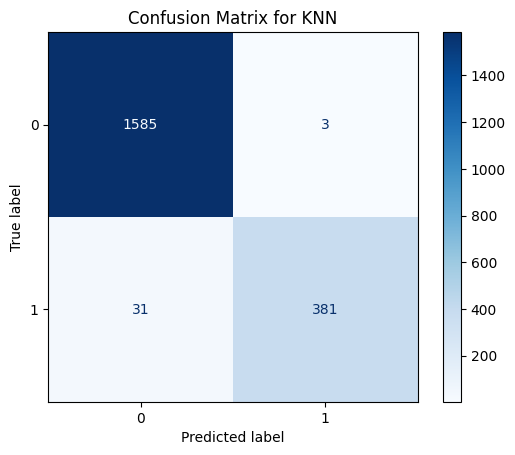

In [10]:
# رسم ماتریس اغما
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap=plt.cm.Blues)
plt.title("Confusion Matrix for KNN")
plt.show()

In [11]:
# display(X[0:5])
# display(X_train_scaled[0:5])

In [12]:
df_org.iloc[6816]

,6816
RowNumber,6817
CustomerId,15662243
Surname,Taylor
CreditScore,559
Geography,France
Gender,Male
Age,50
Tenure,5
Balance,162702.35
NumOfProducts,1


In [13]:
CreditScore = 559
Age = 50
Tenure = 5
Balance = 162702
NumOfProducts = 1
HasCrCard = 0
IsActiveMember = 0
EstimatedSalary = 150548
Complain = 1
Satisfaction_Score = 3
Point_Earned  = 815
Geography_France = 1
Geography_Germany = 0
Geography_Spain = 0
Gender_Female = 0
Gender_Male = 1
Card_Type_DIAMOND = 1
Card_Type_GOLD = 0
Card_Type_PLATINUM = 0
Card_Type_SILVER = 0

vec = [
    CreditScore,
    Age,
    Tenure,
    Balance,
    NumOfProducts,
    HasCrCard,
    IsActiveMember,
    EstimatedSalary,
    Complain,
    Satisfaction_Score,
    Point_Earned,
    Geography_France,
    Geography_Germany,
    Geography_Spain,
    Gender_Female,
    Gender_Male,
    Card_Type_DIAMOND,
    Card_Type_GOLD,
    Card_Type_PLATINUM,
    Card_Type_SILVER,
]

# clf_knn.predict(vec)

vec_2d = np.array(vec).reshape(1, -1)

vec_2d_scaled = scaler.transform(vec_2d)

prediction = clf_knn.predict(vec_2d_scaled)
print("Prediction:", prediction)

Prediction: [1]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [14]:
test_df.head(10)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,...,Point Earned,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male,Card Type_DIAMOND,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
2374,639,29,4,133434.57,2,1,0,97983.44,0,0,...,293,0,0,1,0,1,0,0,1,0
1784,658,36,8,174060.46,1,1,1,94925.62,0,0,...,603,1,0,0,0,1,0,1,0,0
6301,766,45,6,97652.96,1,1,0,127332.33,0,0,...,883,0,1,0,1,0,1,0,0,0
1600,517,28,2,115062.61,1,1,0,179056.23,0,0,...,910,1,0,0,0,1,0,1,0,0
7920,714,34,5,141173.03,1,0,1,98896.06,0,0,...,536,1,0,0,0,1,0,0,0,1
6868,462,39,4,140133.08,2,0,0,131304.45,0,0,...,627,1,0,0,0,1,0,0,0,1
9082,768,36,5,180169.44,2,1,0,17348.56,0,0,...,760,1,0,0,1,0,0,1,0,0
9227,776,31,5,0.00,2,1,0,92647.94,0,0,...,597,1,0,0,1,0,1,0,0,0
6816,559,50,5,162702.35,1,0,0,150548.50,1,1,...,815,1,0,0,0,1,1,0,0,0
1492,735,50,9,0.00,1,0,0,166677.35,1,1,...,886,0,0,1,0,1,0,0,1,0
